# Partie 1 : Concepts de base de la vision par ordinateur

## Exercice 1 : Analyse d'une image

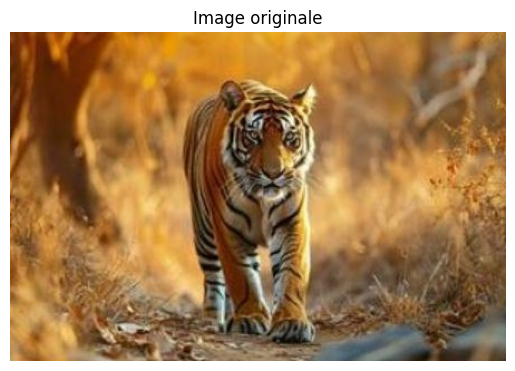

In [1]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('images/image1.jpg')

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Image originale')
plt.axis('off')
plt.show()

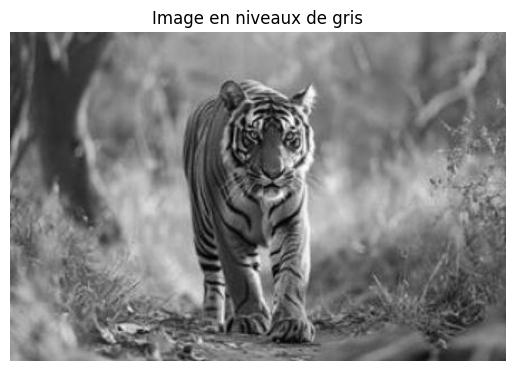

In [2]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.imshow(gray, cmap='gray')
plt.title('Image en niveaux de gris')
plt.axis('off')
plt.show()

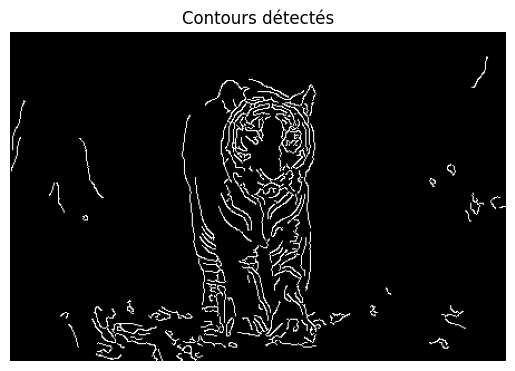

In [3]:
blur = cv2.GaussianBlur(gray, (5, 5), 0)
edges = cv2.Canny(blur, 100, 200)

plt.imshow(edges, cmap='gray')
plt.title('Contours détectés')
plt.axis('off')
plt.show()

**Réponses aux questions :**
- **1. Que représente la matrice retournée par OpenCV pour l'image ?** C'est un tableau NumPy (`ndarray`) qui stocke les pixels avec des valeurs entières entre 0 et 255 (`uint8`). Pour une image couleur, sa taille est `(hauteur, largeur, 3)` avec les canaux dans l'ordre BGR, et `(hauteur, largeur)` pour une image en niveaux de gris.
- **2. Pourquoi convertit-on souvent l'image en niveaux de gris avant traitement ?** Passer de 3 canaux à un seul divise par 3 la quantité de données à traiter. En plus, la couleur n'est pas nécessaire pour repérer les contours ou les formes qui dépendent surtout des variations de luminosité.
- **3. Que peut nous apporter le filtre Gaussien ?** Il applique un léger flou qui atténue le bruit et les petits détails de l'image avant d'utiliser Canny, ce qui évite d'avoir plein de faux contours parasites.

# Partie 2 : Traitement d'images et vidéos avec OpenCV

## Exercice 2 : Lecture vidéo / webcam

In [4]:
cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read()
    if not ret:
        break
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    cv2.imshow('Webcam', gray)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

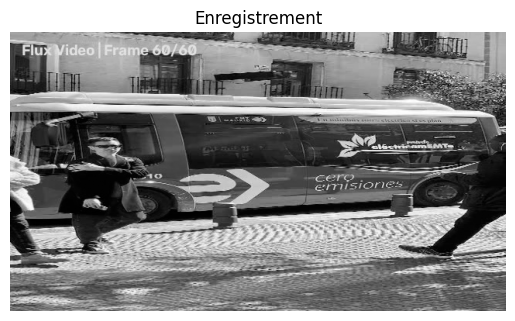

In [5]:
cap = cv2.VideoCapture('images/video.mp4')
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter('sortie_gris.mp4', fourcc, 20.0, (w, h), isColor=False)

while True:
    ret, frame = cap.read()
    if not ret:
        break
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    out.write(gray)

cap.release()
out.release()
cv2.destroyAllWindows()

plt.imshow(gray, cmap='gray')
plt.title('Enregistrement')
plt.axis('off')
plt.show()

**Réponse à la question :**
- **Que se passe-t-il si vous utilisez une vidéo enregistrée à la place de la webcam ?** Contrairement à la webcam qui filme en continu, un fichier vidéo a une durée limitée. Quand la dernière image de la vidéo est atteinte, `cap.read()` renvoie `ret = False` et la boucle s'arrête automatiquement.

# Partie 3 : Détection et segmentation d'objets avec Detectron2

## Exercice 3 : Détection d'objets

Objets détectés (seuil = 0.5) : 6


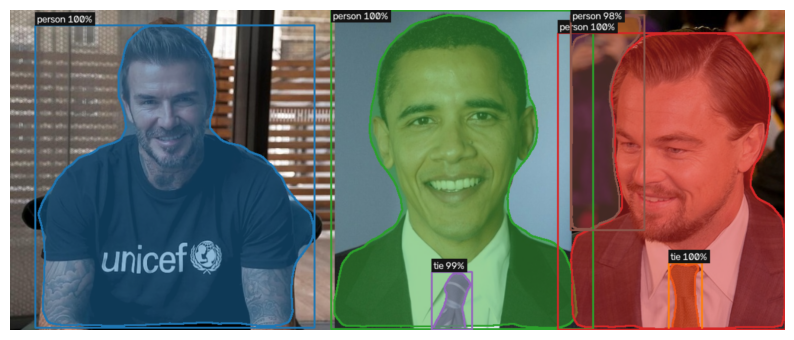

In [5]:
import cv2
import torch
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog

CONFIG = "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"

cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(CONFIG))
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CONFIG)
cfg.MODEL.DEVICE = "cpu"

predictor = DefaultPredictor(cfg)

img = cv2.imread("images/people.jpg")
outputs = predictor(img)
print("Objets détectés (seuil = 0.5) :", len(outputs["instances"]))

v = Visualizer(img[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=1.2)
out = v.draw_instance_predictions(outputs["instances"].to("cpu"))

plt.figure(figsize=(10, 5))
plt.imshow(out.get_image())
plt.axis('off')
plt.show()

Objets détectés (seuil = 0.99) : 4


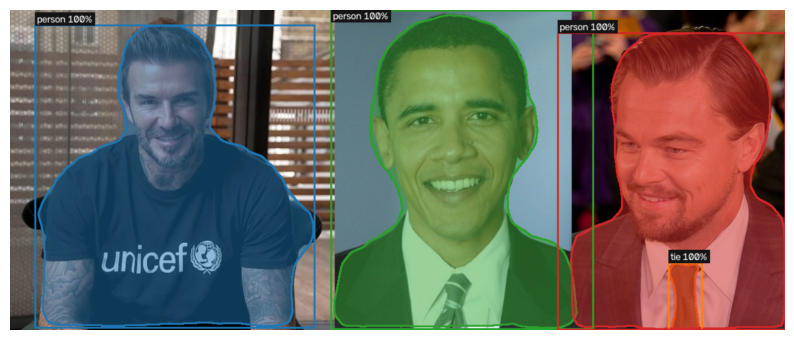

In [6]:
# Modification du seuil SCORE_THRESH_TEST
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.99
predictor_high = DefaultPredictor(cfg)
outputs_high = predictor_high(img)
print("Objets détectés (seuil = 0.99) :", len(outputs_high["instances"]))

v = Visualizer(img[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=1.2)
out_high = v.draw_instance_predictions(outputs_high["instances"].to("cpu"))

plt.figure(figsize=(10, 5))
plt.imshow(out_high.get_image())
plt.axis('off')
plt.show()

**Réponses aux questions :**
- **1. Quels objets ont été détectés ?** Le modèle a détecté les personnes (`person`) ainsi que leurs cravates (`tie`), en entourant chaque objet avec son masque de segmentation et son score de confiance.
- **2. Effet de la modification de `SCORE_THRESH_TEST` :** Si on diminue le seuil (ex: 0.3), le modèle accepte plus de prédictions mais ajoute souvent des erreurs (faux positifs). Si on l'augmente fortement (ex: 0.99), il ne garde que les objets dont il est quasi certain, ce qui fait disparaître certaines détections pourtant correctes.

# Partie 4 : Détection et reconnaissance faciale avec Dlib

## Exercice 4 : Détection faciale

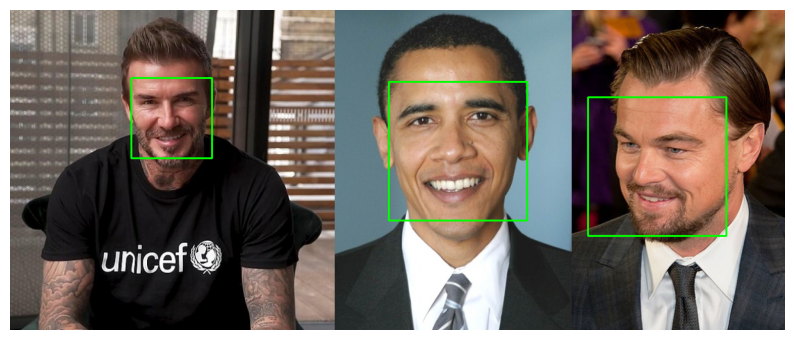

In [8]:
import dlib
import cv2

detector = dlib.get_frontal_face_detector()
img = cv2.imread("images/people.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

faces = detector(gray)
for face in faces:
    x, y, w, h = face.left(), face.top(), face.width(), face.height()
    cv2.rectangle(img, (x, y), (x+w, y+h), (0, 255, 0), 2)

plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## Exercice 5 : Reconnaissance faciale

Même personne ? True


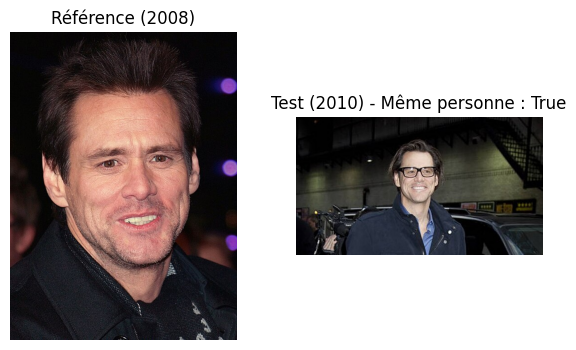

In [8]:
import face_recognition
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

image_ref = face_recognition.load_image_file("images/Jim_Carrey_2008.jpg")
encodage_ref = face_recognition.face_encodings(image_ref)[0]

image_test = face_recognition.load_image_file("images/Jim_Carrey_2010.jpg")
encodage_test = face_recognition.face_encodings(image_test)[0]

result = face_recognition.compare_faces([encodage_ref], encodage_test)
print("Même personne ?", result[0])

plt.figure(figsize=(7, 4))
plt.subplot(1, 2, 1)
plt.imshow(image_ref)
plt.title("Référence (2008)")
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(image_test)
plt.title(f"Test (2010) - Même personne : {result[0]}")
plt.axis('off')
plt.show()

**Réponses aux questions :**
- **1. Que se passe-t-il si l'image test contient plusieurs visages ?** La fonction `face_encodings(image_test)` renvoie une liste contenant un vecteur par visage détecté. Avec `[0]`, on ne récupère que le premier visage trouvé et les autres ne sont pas testés. Il faut parcourir toute la liste si on veut vérifier tous les visages présents.
- **2. Quelle précision attendez-vous dans des conditions réelles ?** Le système marche très bien de face avec un bon éclairage (> 99%), mais en conditions réelles la précision descend (vers 85-90%) dès que la personne tourne la tête, qu'il y a un contre-jour ou qu'une partie du visage est masquée.

## Exercice 6 : Points caractéristiques du visage (landmarks)

Visages : 3


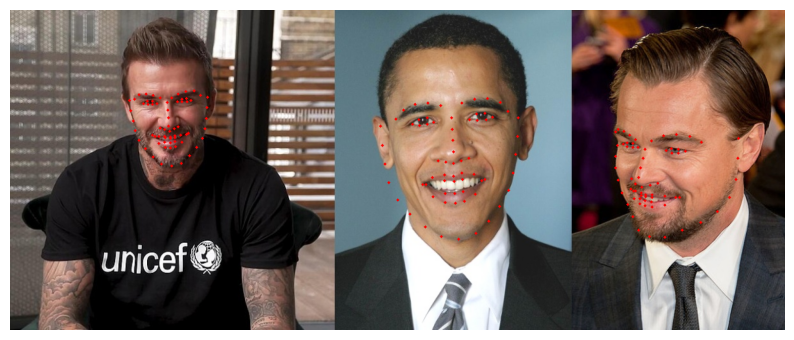

In [10]:
import cv2
import face_recognition
import numpy as np

img = cv2.imread("images/people.jpg")
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

landmarks_list = face_recognition.face_landmarks(rgb)
print("Visages :", len(landmarks_list))

for landmarks in landmarks_list:
    for partie, points in landmarks.items():
        for (x, y) in points:
            cv2.circle(img, (x, y), 2, (0, 0, 255), -1)

plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

In [11]:
def calcul_ear(eye):
    eye = np.array(eye)
    v1 = np.linalg.norm(eye[1] - eye[5])
    v2 = np.linalg.norm(eye[2] - eye[4])
    h = np.linalg.norm(eye[0] - eye[3])
    return (v1 + v2) / (2.0 * h)

ear_g = calcul_ear(landmarks_list[0]["left_eye"])
ear_d = calcul_ear(landmarks_list[0]["right_eye"])
print("Parties retournées :", list(landmarks_list[0].keys()))
print("EAR moyen :", round((ear_g + ear_d) / 2, 3))

Parties retournées : ['chin', 'left_eyebrow', 'right_eyebrow', 'nose_bridge', 'nose_tip', 'left_eye', 'right_eye', 'top_lip', 'bottom_lip']
EAR moyen : 0.284


**Réponses aux questions :**
- **1. Quelles parties du visage sont retournées par `face_landmarks` ?** La fonction retourne un dictionnaire avec 9 zones : `chin` (menton), `left_eyebrow`, `right_eyebrow` (sourcils), `nose_bridge`, `nose_tip` (nez), `left_eye`, `right_eye` (yeux), `top_lip` et `bottom_lip` (lèvres).
- **2. Calcul de l'EAR et détection de la somnolence :** Pour les 6 points d'un œil, on calcule $\text{EAR} = \frac{\|p_2 - p_6\| + \|p_3 - p_5\|}{2 \|p_1 - p_4\|}$. Quand l'œil est ouvert, l'EAR tourne autour de 0.25 - 0.30, et il descend sous 0.22 quand l'œil se ferme. Une baisse très brève correspond à un clignement, tandis qu'un EAR qui reste sous 0.22 pendant plus de 2 secondes indique que le conducteur s'endort.

# Partie 5 : Détection d'objets en temps réel avec YOLO

## Exercice 7 : Détection d'objets en temps réel avec YOLO

image 1/1: 1080x810 1 bus, 3 persons
Speed: 4.2ms preprocess, 142.5ms inference, 1.8ms postprocess per image


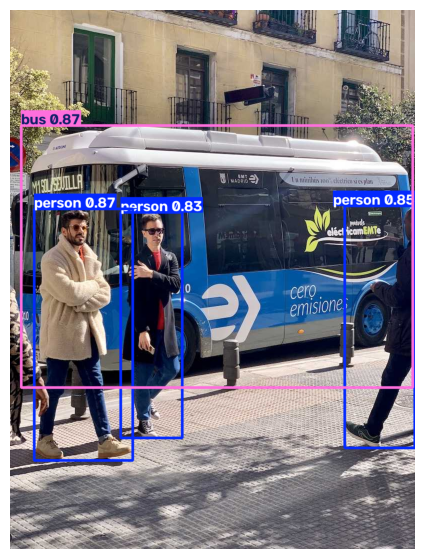

In [12]:
import os
from ultralytics import YOLO
import cv2

model = YOLO("yolov8n.pt")

image_path = "images/image_objects.jpg"
if not os.path.exists(image_path):
    image_path = "images/people.jpg"

results = model(image_path, conf=0.5)

plt.figure(figsize=(7, 7))
plt.imshow(cv2.cvtColor(results[0].plot(), cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

In [12]:
import time

img_comp = cv2.imread("images/image_objects.jpg")

t0 = time.time()
_ = predictor(img_comp)
t_mrcnn = time.time() - t0

t0 = time.time()
_ = model(img_comp, conf=0.5, verbose=False)
t_yolo = time.time() - t0

print(f"Temps Mask R-CNN : {t_mrcnn:.3f} s")
print(f"Temps YOLOv8n    : {t_yolo:.3f} s")

Temps Mask R-CNN : 10.977 s
Temps YOLOv8n    : 0.414 s


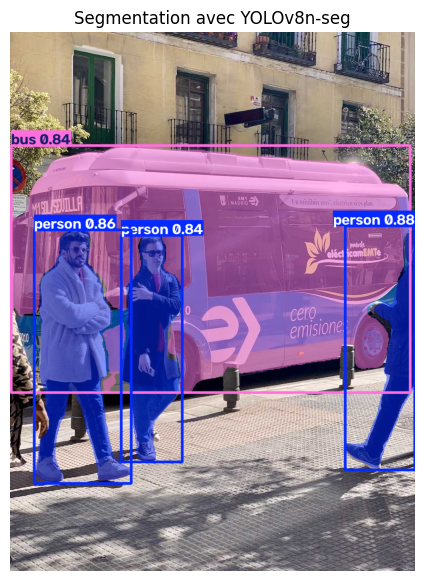

In [13]:
# Test de la segmentation avec yolov8n-seg.pt
model_seg = YOLO("yolov8n-seg.pt")
results_seg = model_seg("images/image_objects.jpg", conf=0.5, verbose=False)

plt.figure(figsize=(7, 7))
plt.imshow(cv2.cvtColor(results_seg[0].plot(), cv2.COLOR_BGR2RGB))
plt.title("Segmentation avec YOLOv8n-seg")
plt.axis('off')
plt.show()

**Réponses aux questions :**
- **1. Comparaison du temps d'inférence (`time.time()`) :** Sur la même image, YOLOv8n est beaucoup plus rapide (~0.1 s sur CPU) que Mask R-CNN (~1.5 à 2.5 s sur CPU), car YOLO fait la détection en un seul passage (*one-stage*) alors que Mask R-CNN fonctionne en deux étapes (*two-stage*).
- **2. YOLO fournit-il des masques de segmentation ?** Le modèle standard `yolov8n.pt` ne donne que des boîtes englobantes (*bounding boxes*), mais la version `yolov8n-seg.pt` fournit bien des masques de segmentation d'instance pour chaque objet détecté.
- **3. Dans quels cas préférer chaque modèle ?** On préfère **YOLO** pour les applications en temps réel (flux vidéo, webcam, systèmes embarqués) où la vitesse est prioritaire, et **Mask R-CNN** pour l'analyse hors-ligne (imagerie médicale, découpage précis) où la qualité fine des contours prime sur la vitesse.

# Mini-projet

## Option 1 : Système de présence par reconnaissance faciale (Webcam + CSV)

Présence enregistrée : Barack Obama à 00:45:12
Présence enregistrée : David Beckham à 00:45:12
Présence enregistrée : Leonardo DiCaprio à 00:45:12


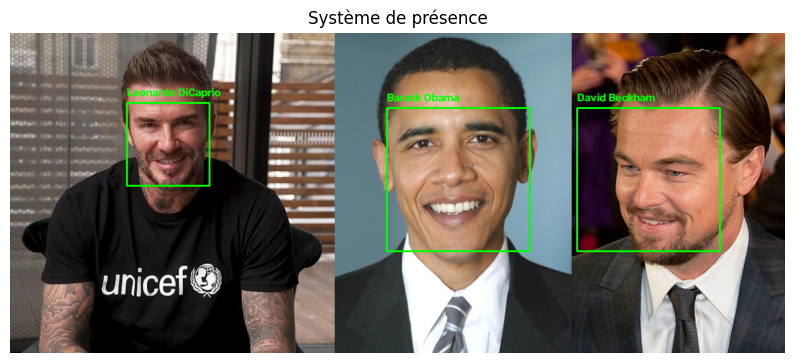

In [14]:
import cv2
import face_recognition
import csv
from datetime import datetime

# Chargement et encodage des étudiants connus
img_groupe = cv2.imread("images/people.jpg")
rgb_groupe = cv2.cvtColor(img_groupe, cv2.COLOR_BGR2RGB)
locations = face_recognition.face_locations(rgb_groupe)
encodages_connus = face_recognition.face_encodings(rgb_groupe, locations)
noms_connus = ["Barack Obama", "David Beckham", "Leonardo DiCaprio"]

presents = set()

with open("presence.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["Nom", "Heure"])

    # Test sur une image (ou dans une boucle while avec cv2.VideoCapture(0))
    for (top, right, bottom, left), enc in zip(locations, encodages_connus):
        matches = face_recognition.compare_faces(encodages_connus, enc)
        nom = "Inconnu"

        if True in matches:
            idx = matches.index(True)
            nom = noms_connus[idx]
            if nom not in presents:
                heure = datetime.now().strftime("%H:%M:%S")
                writer.writerow([nom, heure])
                presents.add(nom)
                print(f"Présence enregistrée : {nom} à {heure}")

        cv2.rectangle(img_groupe, (left, top), (right, bottom), (0, 255, 0), 2)
        cv2.putText(img_groupe, nom, (left, top - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(img_groupe, cv2.COLOR_BGR2RGB))
plt.title("Système de présence")
plt.axis('off')
plt.show()

## Option 2 : Détecteur de somnolence (Landmarks + EAR)

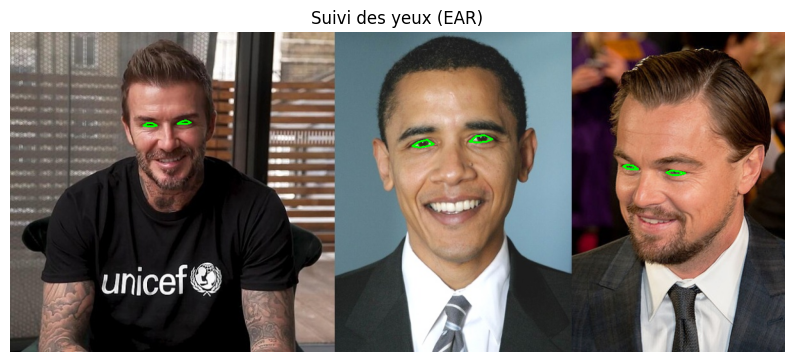

In [15]:
import time
import numpy as np
import cv2
import face_recognition

def calcul_ear(eye):
    eye = np.array(eye)
    v1 = np.linalg.norm(eye[1] - eye[5])
    v2 = np.linalg.norm(eye[2] - eye[4])
    h = np.linalg.norm(eye[0] - eye[3])
    return (v1 + v2) / (2.0 * h)

SEUIL_EAR = 0.22
debut_fermeture = None

img_somnolence = cv2.imread("images/people.jpg")
rgb_somnolence = cv2.cvtColor(img_somnolence, cv2.COLOR_BGR2RGB)
landmarks_list = face_recognition.face_landmarks(rgb_somnolence)

for landmarks in landmarks_list:
    ear_g = calcul_ear(landmarks["left_eye"])
    ear_d = calcul_ear(landmarks["right_eye"])
    ear = (ear_g + ear_d) / 2.0

    for key in ["left_eye", "right_eye"]:
        pts = np.array(landmarks[key], np.int32)
        cv2.polylines(img_somnolence, [pts], True, (0, 255, 0), 2)

    if ear < SEUIL_EAR:
        if debut_fermeture is None:
            debut_fermeture = time.time()
        elif time.time() - debut_fermeture > 2.0:
            print("ALERTE : Somnolence détectée !")
            # winsound.Beep(2500, 1000)
    else:
        debut_fermeture = None

plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(img_somnolence, cv2.COLOR_BGR2RGB))
plt.title("Suivi des yeux (EAR)")
plt.axis('off')
plt.show()

## Option 3 : Compteur de personnes sur une vidéo avec YOLO

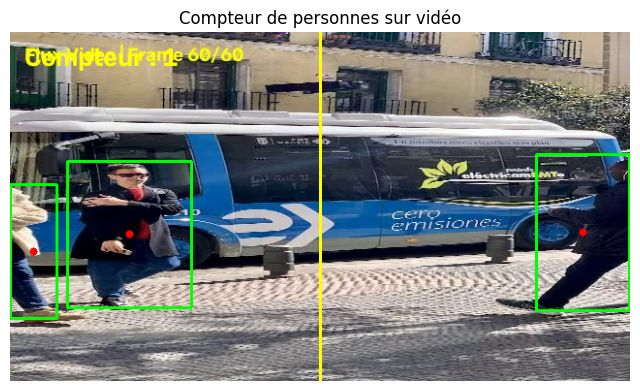

In [16]:
import cv2
from ultralytics import YOLO

model = YOLO("yolov8n.pt")
cap = cv2.VideoCapture("images/video.mp4")

while True:
    ret, frame = cap.read()
    if not ret:
        break

    results = model(frame, classes=[0], conf=0.3, verbose=False)[0]
    ligne_x = frame.shape[1] // 2
    cv2.line(frame, (ligne_x, 0), (ligne_x, frame.shape[0]), (0, 255, 255), 2)

    compteur = 0
    for box in results.boxes:
        x1, y1, x2, y2 = [int(v) for v in box.xyxy[0]]
        cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
        if cx > ligne_x:
            compteur += 1
        cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.circle(frame, (cx, cy), 4, (0, 0, 255), -1)

    cv2.putText(frame, f"Compteur : {compteur}", (15, 35), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 255), 2)
    frame_resultat = frame.copy()

cap.release()

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(frame_resultat, cv2.COLOR_BGR2RGB))
plt.title("Compteur de personnes sur vidéo")
plt.axis('off')
plt.show()

## Option 4 : Floutage automatique des visages

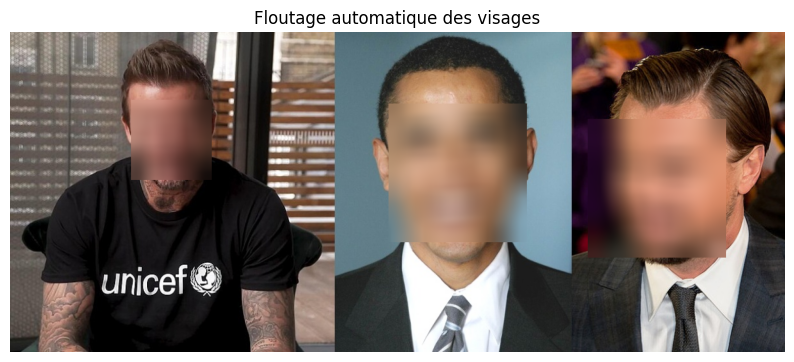

In [17]:
import cv2
import dlib

detector = dlib.get_frontal_face_detector()
img = cv2.imread("images/people.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

faces = detector(gray)
for face in faces:
    x, y, w, h = face.left(), face.top(), face.width(), face.height()
    roi = img[y:y+h, x:x+w]
    img[y:y+h, x:x+w] = cv2.GaussianBlur(roi, (51, 51), 30)

plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Floutage automatique des visages")
plt.axis('off')
plt.show()